# Cartera dedicada · Renta fija

**Objetivo.** Aislar la renta fija para separar dos riesgos que suelen confundirse: la duración
(sensibilidad a los tipos de interés) y el crédito (probabilidad de impago).

- **Universo:** cinco ETF estadounidenses de bonos: `SHY` (Treasury 1–3 años), `IEF` (Treasury 7–10
  años), `TLT` (Treasury 20+ años), `LQD` (crédito investment grade) y `HYG` (high yield).
- **Moneda:** USD. La biblioteca no convierte divisas, así que todos los ejemplos usan una sola moneda.
- **Ventana:** desde `2025-01-02` hasta la última sesión disponible.
- **Anualización:** 252 sesiones.

`auto_adjust=True` incorpora los cupones al precio, de modo que la serie se aproxima a la
rentabilidad total del ETF y no solo a su precio limpio.

Datos hasta la última sesión disponible anterior a `END` (2026-11-06).

In [1]:
"""Cartera dedicada de renta fija: ingesta, informe y simulación."""

import warnings

from IPython.display import Markdown

from quantfolio import (
    CachedPriceSource,
    FredMacroSource,
    MonteCarloParameters,
    Portfolio,
    YahooFinanceSource,
)

#: yfinance todavía usa argumentos ``inplace`` que pandas 3 marca como obsoletos.
warnings.filterwarnings("ignore", message=".*inplace keyword.*")

START = "2025-01-02"
END = "2026-11-06"
TICKERS = ["SHY", "IEF", "TLT", "LQD", "HYG"]
WEIGHTS = {"SHY": 0.20, "IEF": 0.20, "TLT": 0.20, "LQD": 0.20, "HYG": 0.20}
PERIODS_PER_YEAR = 252

## 1 · Ingesta

Los cinco ETF se descargan con `get_many()` y se normalizan en `PriceSeries`. La caché CSV evita
repetir la descarga mientras los datos sigan siendo recientes.

In [2]:
source = CachedPriceSource(YahooFinanceSource(), cache_dir="data")
assets = source.get_many(TICKERS, start=START, end=END)

for ticker, asset in assets.items():
    print(
        f"{ticker:>5} | {asset.source:<18} | "
        f"{asset.prices.index.min().date()} → {asset.prices.index.max().date()} | "
        f"{len(asset.prices)} observaciones"
    )

  SHY | Yahoo Finance      | 2025-01-02 → 2026-11-05 | 463 observaciones
  IEF | Yahoo Finance      | 2025-01-02 → 2026-11-05 | 463 observaciones
  TLT | Yahoo Finance      | 2025-01-02 → 2026-11-05 | 463 observaciones
  LQD | Yahoo Finance      | 2025-01-02 → 2026-11-05 | 463 observaciones
  HYG | Yahoo Finance      | 2025-01-02 → 2026-11-05 | 463 observaciones


## 2 · Cartera

`Portfolio` valida que haya un peso por activo, normaliza los pesos y alinea los calendarios por
intersección. La cobertura indica qué fechas conserva el análisis después de esa alineación.

In [3]:
portfolio = Portfolio(assets=assets, weights=WEIGHTS)

print("Pesos normalizados:")
for ticker, weight in portfolio.weights.items():
    print(f"  {ticker}: {weight:.2%}")

print("\nDiagnóstico de alineación temporal:", portfolio.alignment_summary())

Pesos normalizados:
  SHY: 20.00%
  IEF: 20.00%
  TLT: 20.00%
  LQD: 20.00%
  HYG: 20.00%

Diagnóstico de alineación temporal: {'union_dates': 463, 'common_dates': 463, 'coverage': 1.0, 'multi_day_returns': 101, 'multi_day_share': 0.21908893709327548, 'max_gap_days': 4}


## 3 · Informe

El informe Markdown reúne la composición, las métricas anualizadas, la calidad de los datos y las
advertencias de riesgo. Las advertencias se calculan a partir del estado real de la cartera.

In [4]:
Markdown(portfolio.report(periods_per_year=PERIODS_PER_YEAR))

# Informe de la cartera

## 1. Composición

| Activo | Peso |
|---|---:|
| SHY | 20.00% |
| IEF | 20.00% |
| TLT | 20.00% |
| LQD | 20.00% |
| HYG | 20.00% |

## 2. Métricas históricas

| Métrica | Valor |
|---|---:|
| Rentabilidad media diaria | 0.0120% |
| Volatilidad diaria | 0.3249% |
| Rentabilidad anualizada aproximada | 3.02% |
| Volatilidad anualizada | 5.16% |
| Error estándar de la rentabilidad anualizada | 3.81% |
| IC 95% de la rentabilidad anualizada | -4.45% - 10.48% |
| Rentabilidad geométrica (CAGR) | 2.93% |
| Deriva del logaritmo usada por Monte Carlo | 2.89% |
| Crecimiento mediano implícito (exp(m)-1) | 2.93% |
| Máxima caída histórica | -5.67% |
| Ratio de Sharpe (rf=0.00%) | 0.59 |
| VaR histórico diario (95%) | 0.49% |
| CVaR histórico diario (95%) | 0.70% |

_Un VaR o CVaR negativo indica que el cuantil de la cola es una ganancia._

_La simulación usa la deriva del logaritmo; su mediana crece a exp(m)-1, no a la rentabilidad aritmética._

## 3. Calidad de los datos

- Activos: 5
- Fechas en la unión de calendarios: 463
- Fechas comunes a todos los activos: 463
- Cobertura tras la alineación: 100.0%
- Intervalos entre retornos que abarcan más de un día natural: 21.9% (máximo 4 días)
- Observaciones de rentabilidad: 462
- Periodo de la muestra: 2025-01-03 → 2026-11-05
- Años de historia: 1.83

**Cobertura por activo**

| Activo | Observaciones | Inicio | Fin |
|---|---:|---|---|
| SHY | 463 | 2025-01-02 | 2026-11-05 |
| IEF | 463 | 2025-01-02 | 2026-11-05 |
| TLT | 463 | 2025-01-02 | 2026-11-05 |
| LQD | 463 | 2025-01-02 | 2026-11-05 |
| HYG | 463 | 2025-01-02 | 2026-11-05 |

## 4. Advertencias de riesgo

- Las rentabilidades históricas no garantizan resultados futuros.
- La simulación de Monte Carlo depende de los supuestos de rentabilidad y volatilidad.
- El 21.9% de los intervalos entre retornos abarca más de un día natural; la anualización con 252 o 365 periodos es aproximada.

## 4 · Panel analítico

El primer panel muestra la evolución de precios **reajustada a base 100**, para que activos con
precios nominales distintos se puedan comparar. Los otros tres paneles muestran la rentabilidad
acumulada, la matriz de correlación y el valor de la cartera.

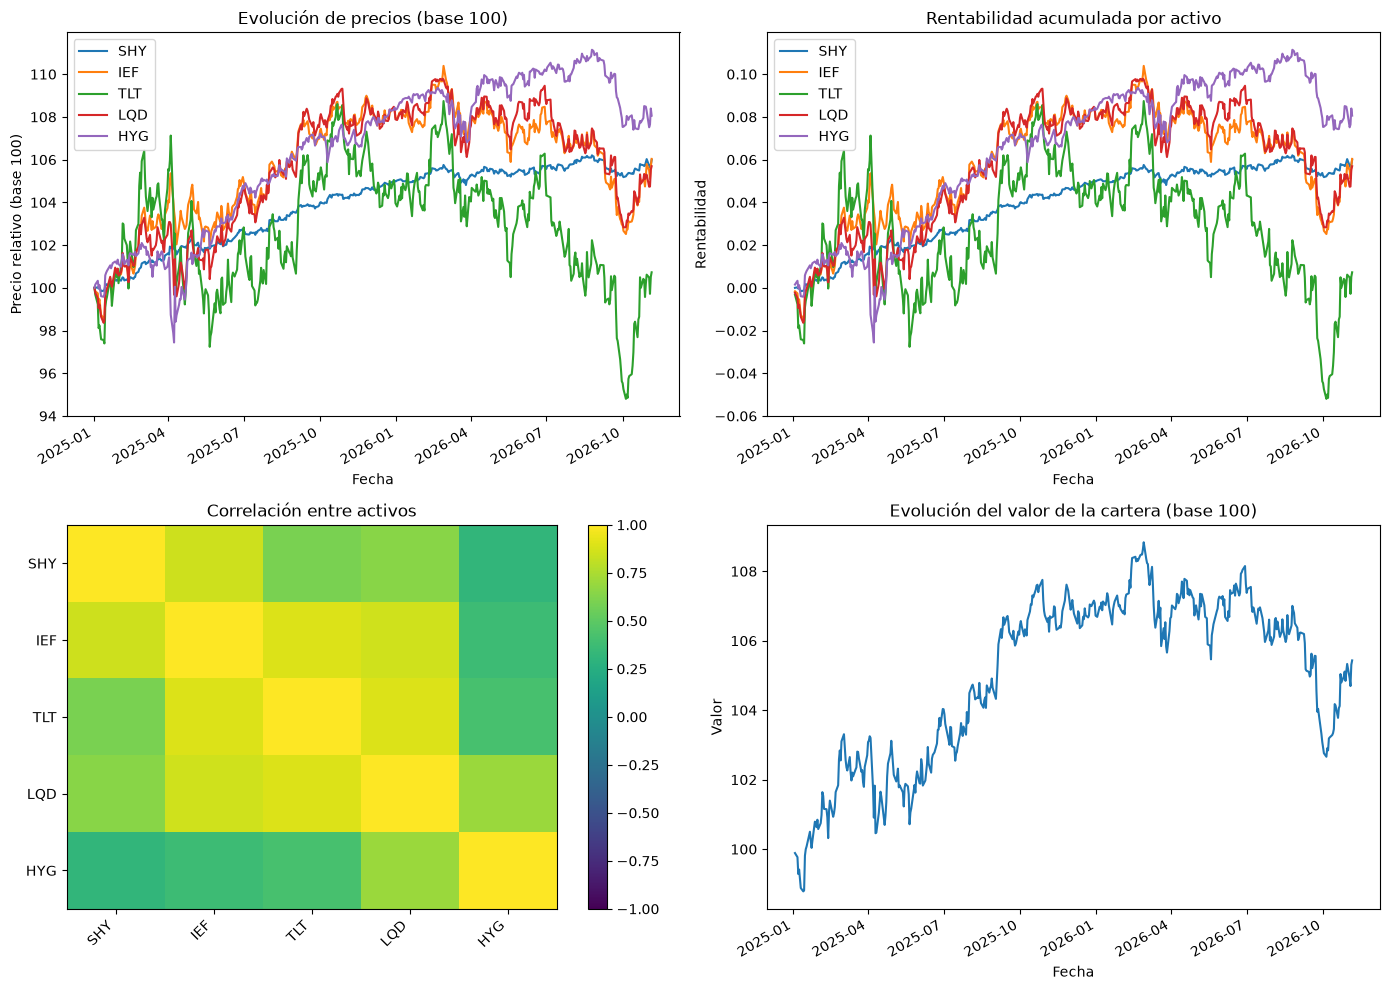

In [5]:
portfolio.plots_report()

## 5 · Contexto macro

El rendimiento del Treasury a 10 años (`DGS10`) es contexto macro, no un activo de la cartera. Sirve
para relacionar la evolución de los precios de los bonos con los tipos de interés: cuando el
rendimiento sube, el precio de un bono con duración positiva tiende a bajar.

In [6]:
fred = FredMacroSource()
rates = fred.get_series("DGS10", start=START, end=END)
print(f"Tipo del Treasury a 10 años (%): {rates.values.tail(3).round(2).to_list()}")

Tipo del Treasury a 10 años (%): [4.91, 4.95, 4.9]


## 6 · Simulación Monte Carlo

La simulación usa la deriva y la volatilidad logarítmicas estimadas de la historia. El horizonte
se expresa en los mismos periodos que la anualización de la cartera, de modo que el número de
pasos y los supuestos compartan el mismo calendario. La distribución final permite leer el abanico
de resultados, no una predicción puntual.

count     2000.00
mean     10304.20
std        542.11
min       8762.45
5%        9443.84
50%      10273.97
95%      11280.05
max      12095.33
Name: 252, dtype: float64


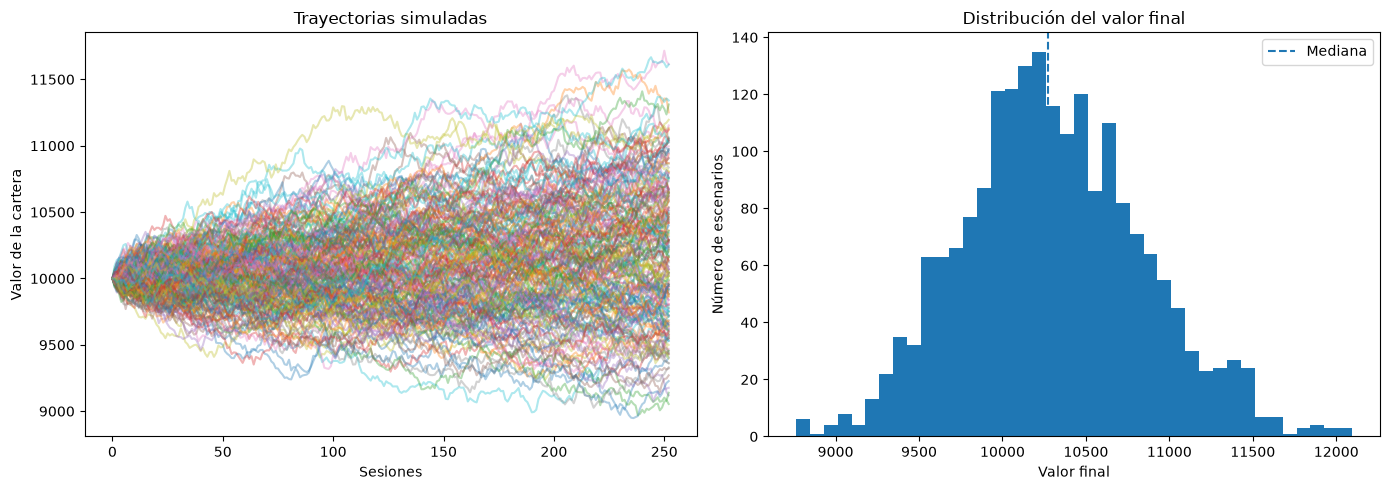

In [7]:
simulations = portfolio.simulate_monte_carlo(
    MonteCarloParameters(
        n_paths=2_000,
        horizon=PERIODS_PER_YEAR,
        periods_per_year=PERIODS_PER_YEAR,
        seed=42,
    )
)

final_values = simulations.iloc[-1]
print(final_values.describe(percentiles=[0.05, 0.5, 0.95]).round(2))
portfolio.plot_simulation(simulations, max_paths=200)

## 7 · Qué aporta esta clase

La duración y el crédito son riesgos distintos. Los Treasury suelen diversificar a la renta variable
en episodios de aversión al riesgo, mientras que el high yield se comporta más como equity cuando el
ciclo se deteriora. En una cartera multi-activo, la renta fija aporta estabilidad y flujos, pero no
es un refugio perfecto: también tiene volatilidad y riesgo de tipos.